# Radar de Licitaciones — Evaluación

**Milton Beltrán** · Natural Language Processing · Proyecto final

**Fuente:** API OCDS de Guatecompras ([`ocds.guatecompras.gt/files`](https://ocds.guatecompras.gt/files)), Ministerio de Finanzas Públicas, licencia CC BY 4.0.

En este notebook medimos qué tan bien funciona el radar. Comparamos cinco formas de armar la lista del día. Las dos primeras son las líneas base de la propuesta, un filtro por palabra clave y otro por categoría UNSPSC de TI. Las otras tres son las señales del modelo, el clasificador TF-IDF con regresión logística, la similitud con embeddings contra el portafolio de ALBRAN y el score que combina las dos, que es lo que termina viendo el usuario.

Las métricas son la precisión@10 por día, el recall y el AUC-PR. La principal es la precisión@10, porque es justo lo que ve ALBRAN cada mañana, una lista de diez concursos, y lo que importa es cuántos de esos valen la pena. El AUC-PR mide el orden en todo el rango y aguanta bien el desbalance.

Accuracy no la usamos. Con tan pocos positivos, un modelo que dice siempre que nada es relevante sacaría casi cien por ciento y no serviría para nada.

## 0. Preparación del entorno

In [1]:
# --- 0.1 Librerías, conexión y modelos ---
# La lógica vive en src/; aquí solo se mide y se documenta.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import average_precision_score, precision_recall_curve

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.db import conectar
from src.etiquetado.pooling import elegir_dias
from src.limpieza.normalizar import para_tfidf
from src.modelo.clasificador import cargar, puntuar
from src.modelo.ranking import (
    METODOS, ajustar_alfa, candidatos, es_venta_computo, explicar, lista_del_dia, puntajes, top,
)
from src.modelo.similitud import cargar_portafolio, embeber, similitud

con = conectar(solo_lectura=True)
modelo, VERSION = cargar()
proyectos, emb_portafolio = cargar_portafolio()
IMG = RAIZ / "img"
IMG.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 100)
print(f"Modelo {VERSION} · portafolio con {len(proyectos)} filas")

Modelo tfidf-rl-150et-20261116 · portafolio con 7 filas


In [2]:
# --- 0.2 Estilo de las gráficas ---
# Misma paleta que el notebook 01: acento para lo que se resalta, gris para el resto.
ACENTO, GRIS, TINTA, TINTA_2 = "#5543D1", "#B9B6AE", "#1E2329", "#5C636B"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": "#D5D3CC", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
})
NOMBRES = {
    "palabra_clave": "Palabra clave", "categoria": "Categoría UNSPSC",
    "clasificador": "Clasificador TF-IDF + RL", "similitud": "Similitud (embeddings)",
    "combinado": "Combinado (tope de 5 cómputo)", "combinado_sin_tope": "Combinado sin tope",
}

## 1. Datos de evaluación

In [3]:
# --- 1.1 Etiquetas por conjunto ---
# Entrenamiento y validación salen del muestreo (70 % pre-filtro, 30 % aleatorio); prueba, del pooling.
etiquetas = con.execute("""
    SELECT conjunto, count(*) AS etiquetados, sum(etiqueta_humana::INT) AS relevantes
    FROM etiquetas WHERE etiqueta_humana IS NOT NULL GROUP BY conjunto
""").df().set_index("conjunto").loc[["entrenamiento", "validacion", "prueba"]]
etiquetas["% relevantes"] = (100 * etiquetas["relevantes"] / etiquetas["etiquetados"]).round(1)
etiquetas

,etiquetados,relevantes,% relevantes
conjunto,,,
entrenamiento,150,41.0,27.3
validacion,150,52.0,34.7
prueba,138,74.0,53.6


In [4]:
# --- 1.2 Días de prueba ---
# Cuatro días hábiles de 2026 con volumen normal, al azar con semilla fija.
DIAS = elegir_dias(con)
pd.DataFrame({
    "día": [f"{d:%a %d/%m/%Y}" for d in DIAS],
    "procesos vigentes": [len(candidatos(con, d)) for d in DIAS],
})

,día,procesos vigentes
0,Wed 04/03/2026,1578
1,Fri 08/05/2026,1548
2,Thu 01/10/2026,1290
3,Thu 08/10/2026,1188


#### ¿Cómo dividimos los datos?

La división es temporal y no aleatoria, porque así se usa el radar en la realidad. Entrenamos con enero 2024 a junio 2025, validamos con julio a diciembre 2025 y probamos con días de 2026. Si mezcláramos fechas, el modelo vería concursos del futuro al entrenar y la medición saldría inflada.

Entrenamiento y validación salen del mismo muestreo, 70 % de procesos que pasan el pre-filtro y 30 % al azar del resto. Sin el pre-filtro casi no habríamos encontrado positivos, y sin la parte aleatoria el modelo nunca vería cómo es un día normal, que es casi todo compra médica.

#### ¿Por qué etiquetamos la prueba con pooling?

Etiquetar los 1,200 a 1,600 procesos de cada día no era posible. Lo que hicimos fue elegir cuatro días hábiles al azar, correr los cinco métodos en cada uno, juntar sus top 10 y etiquetar esa unión a ciegas, sin saber qué método había elegido cada proceso ni qué probabilidad le daba el modelo. Así los cinco métodos se comparan sobre las mismas etiquetas y ninguno juega de local.

Por eso el porcentaje de relevantes de prueba no es la tasa real. Sale alto porque el pool solo junta lo mejor de cada método, mientras que en un día cualquiera lo relevante anda cerca del 2 %.

## 2. Ajuste de α

In [5]:
# --- 2.1 Señales en validación ---
val = con.execute("""
    SELECT p.ocid, p.texto_tfidf, p.texto_embedding, e.origen_muestra, e.etiqueta_humana::INT AS y
    FROM etiquetas e JOIN procesos p USING (ocid)
    WHERE e.conjunto = 'validacion' AND e.etiqueta_humana IS NOT NULL ORDER BY p.ocid
""").df()
val["p"] = puntuar(modelo, val["texto_tfidf"])
val["sim"], val["proyecto"] = similitud(embeber(val["texto_embedding"]), proyectos, emb_portafolio)
ALFA, auc_combinado = ajustar_alfa(val["p"].values, val["sim"].values, val["y"].values)
print(f"α = {ALFA} · AUC-PR en validación: clasificador {average_precision_score(val.y, val.p):.3f}, "
      f"similitud {average_precision_score(val.y, val.sim):.3f}, combinado {auc_combinado:.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

α = 0.65 · AUC-PR en validación: clasificador 0.961, similitud 0.849, combinado 0.972


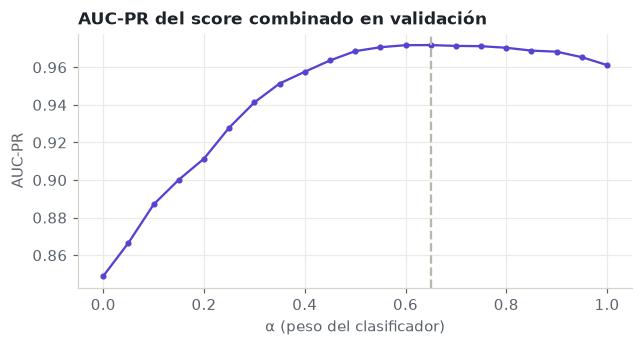

In [6]:
# --- 2.2 AUC-PR en validación según α ---
alfas = np.arange(0, 1.001, 0.05)
curva = [average_precision_score(val.y, a * val.p + (1 - a) * val.sim) for a in alfas]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(alfas, curva, color=ACENTO, marker="o", markersize=3)
ax.axvline(ALFA, color=GRIS, linestyle="--")
ax.set(title="AUC-PR del score combinado en validación", xlabel="α (peso del clasificador)", ylabel="AUC-PR")
fig.savefig(IMG / "alfa_validacion.png");

Con α = 0 solo cuenta la similitud y el AUC-PR en validación es 0.849. Con α = 1 solo cuenta el clasificador y llega a 0.961. El máximo está en α = 0.65, con 0.972.

| α | 0 | 0.3 | 0.5 | 0.65 | 0.8 | 1 |
|---|---|---|---|---|---|---|
| AUC-PR | 0.849 | 0.941 | 0.969 | 0.972 | 0.970 | 0.961 |

La curva sube rápido hasta 0.5 y de ahí queda casi plana, así que el valor exacto de α no es delicado. Cualquier cosa entre 0.5 y 0.9 da prácticamente lo mismo. Lo que sí se ve es que la similitud aporta encima del clasificador, aunque poco, alrededor de un punto de AUC-PR. La señal fuerte es el clasificador.

Hay que tomar estos números con cuidado. La validación tiene 70 % de procesos del pre-filtro, que son los casos que ya traen vocabulario de TI y se separan más fácil. En un día real la mezcla es mucho más difícil, y por eso la cifra que mide el producto es la de prueba de la sección 3.

## 3. Comparación de los cinco métodos

In [7]:
# --- 3.1 Ranking de cada día y etiquetas del pooling ---
etq = dict(con.execute(
    "SELECT ocid, etiqueta_humana FROM etiquetas WHERE conjunto = 'prueba'"
).fetchall())
VARIANTES = [(m, m, -1) for m in METODOS] + [("combinado_sin_tope", "combinado", None)]

por_dia, tops, pool, del_dia = [], {}, [], {}
for dia in DIAS:
    puntuados = puntajes(candidatos(con, dia), modelo, ALFA, (proyectos, emb_portafolio))
    del_dia[dia] = puntuados
    relevantes_dia = sum(bool(etq.get(o)) for o in puntuados["ocid"])
    pool.append(puntuados[puntuados["ocid"].isin(etq)].assign(dia=dia))
    for nombre, metodo, tope in VARIANTES:
        seleccion = top(puntuados, metodo, max_computo=tope).assign(dia=dia)
        tops[(nombre, dia)] = seleccion
        aciertos = sum(bool(etq.get(o)) for o in seleccion["ocid"])
        por_dia.append({"método": nombre, "día": f"{dia:%d/%m}", "p@10": aciertos / 10,
                        "recall": aciertos / relevantes_dia})
por_dia = pd.DataFrame(por_dia)
pool = pd.concat(pool, ignore_index=True)
pool["y"] = pool["ocid"].map(etq).astype(int)
sin_etiqueta = sum(o not in etq for t in tops.values() for o in t["ocid"])
print(f"Pool etiquetado: {len(pool)} procesos, {pool.y.sum()} relevantes · tops sin etiqueta: {sin_etiqueta}")

Pool etiquetado: 114 procesos, 60 relevantes · tops sin etiqueta: 0


In [8]:
# --- 3.2 Precisión@10 por día ---
por_dia.pivot(index="método", columns="día", values="p@10").rename(index=NOMBRES)

día,01/10,04/03,08/05,08/10
método,,,,
Categoría UNSPSC,0.6,0.7,0.6,0.7
Clasificador TF-IDF + RL,1.0,0.7,1.0,1.0
Combinado (tope de 5 cómputo),0.7,0.9,0.8,0.8
Combinado sin tope,1.0,0.9,0.9,1.0
Palabra clave,0.4,0.2,0.2,0.2
Similitud (embeddings),0.7,0.3,0.9,0.8


In [9]:
# --- 3.3 Tabla comparativa ---
# AUC-PR sobre el pool etiquetado de los cuatro días (mismo conjunto para todos los métodos).
tabla = por_dia.groupby("método")[["p@10", "recall"]].mean()
tabla["AUC-PR"] = [
    average_precision_score(pool["y"], pool["combinado" if m == "combinado_sin_tope" else m])
    for m in tabla.index
]
tabla = tabla.sort_values(["p@10", "AUC-PR"], ascending=False).rename(index=NOMBRES)
tabla.round(3)

,p@10,recall,AUC-PR
método,,,
Combinado sin tope,0.950,0.653,0.939
Clasificador TF-IDF + RL,0.925,0.625,0.945
Combinado (tope de 5 cómputo),0.800,0.565,0.939
Similitud (embeddings),0.675,0.446,0.739
Categoría UNSPSC,0.650,0.455,0.738
Palabra clave,0.250,0.165,0.500


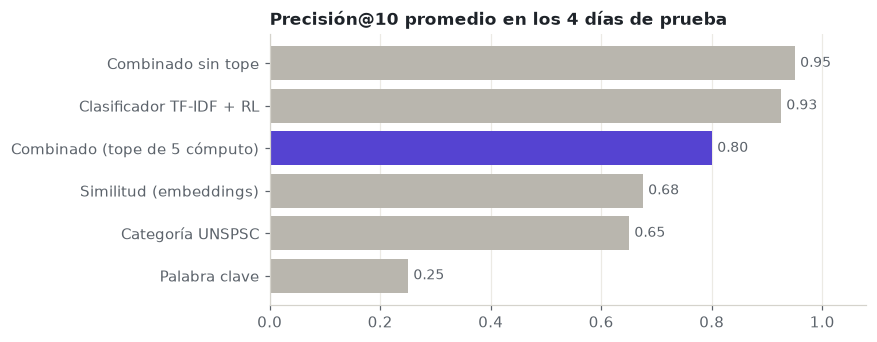

In [10]:
# --- 3.4 Gráfica de precisión@10 ---
orden = tabla.sort_values("p@10")
colores = [ACENTO if "Combinado (tope" in m else GRIS for m in orden.index]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(orden.index, orden["p@10"], color=colores)
for y, v in enumerate(orden["p@10"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=TINTA_2, fontsize=9)
ax.set(title="Precisión@10 promedio en los 4 días de prueba", xlim=(0, 1.08))
ax.grid(axis="y", visible=False)
fig.savefig(IMG / "precision_at_10.png");

El clasificador le gana por mucho a las dos líneas base de la propuesta. Acierta 9.25 de cada 10 en promedio, contra 6.5 de la categoría UNSPSC y 2.5 de la palabra clave. Al sumarle la similitud, el combinado sin tope sube a 9.5.

La palabra clave falla tanto por lo que ya habíamos visto en la exploración (H-11). Palabras como «sistema» o «desarrollo» traen sistemas de agua potable, alcantarillados y nombres de instituciones, y «licencia» o «derecho de uso» traen software que ALBRAN no revende. La categoría funciona mejor porque las computadoras sí vienen con UNSPSC 43, pero en esa misma categoría caen el tóner, las impresoras y las licencias de producto, y se le escapa el software que la entidad clasificó como consultoría.

La similitud sola queda casi empatada con la categoría (0.68 contra 0.65). Funciona bien los días con muchas computadoras, porque se parecen a la fila de venta de cómputo del portafolio, y mal el 4 de marzo (0.3), un día con menos computadoras.

Ojo con el tamaño. Son cuatro días y cuarenta posiciones por método, así que una diferencia como la del combinado sin tope y el clasificador (0.95 contra 0.93) es un solo acierto. La diferencia con las líneas base sí es clara.

## 4. Curvas precisión-recall

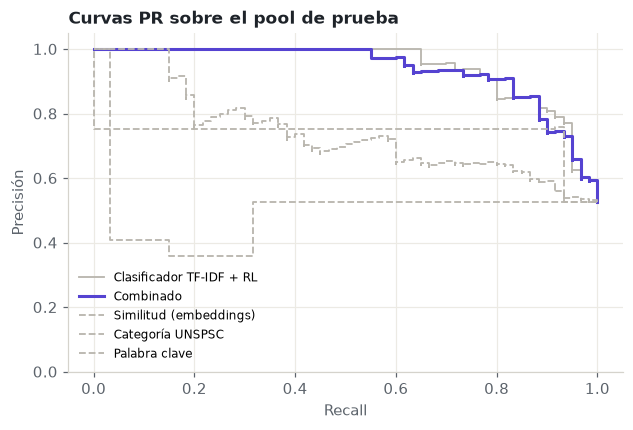

In [11]:
# --- 4.1 Curvas PR sobre el pool de prueba ---
fig, ax = plt.subplots(figsize=(6.5, 4))
for m in ["clasificador", "combinado", "similitud", "categoria", "palabra_clave"]:
    precision, recall, _ = precision_recall_curve(pool["y"], pool[m])
    destacado = m == "combinado"
    ax.step(recall, precision, where="post", color=ACENTO if destacado else GRIS,
            linewidth=2 if destacado else 1.2, label=NOMBRES[m].replace(" (tope de 5 cómputo)", ""),
            linestyle="-" if m in ("combinado", "clasificador") else "--")
ax.set(title="Curvas PR sobre el pool de prueba", xlabel="Recall", ylabel="Precisión", ylim=(0, 1.05))
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig(IMG / "curvas_pr.png");

Las curvas confirman la tabla. El clasificador y el combinado van casi juntos, con precisión perfecta hasta un recall de 0.55 y arriba de 0.9 hasta cerca de 0.8. La similitud empieza bien pero baja antes de 0.2 y termina rondando 0.6. La categoría es casi una línea plana en 0.75, porque su puntaje (la fracción de códigos de TI) empata en muchísimos procesos y no sirve para ordenar dentro del filtro. La palabra clave cae a 0.4 casi de entrada y no pasa de 0.53, porque desde el principio mezcla agua potable con software.

Hay que leer el recall con cuidado. El pool solo tiene los procesos que algún método puso en su top 10, así que el recall es relativo a los relevantes que entraron al pool y no a todos los relevantes del día. Si un concurso relevante no lo eligió ningún método, no aparece en ninguna curva.

## 5. Tope de computadoras en la lista del día

In [12]:
# --- 5.1 Con tope y sin tope ---
# El tope deja como máximo 5 ventas de cómputo; los lugares que sobran pasan a los siguientes por score.
filas = []
for dia in DIAS:
    con_tope, sin_tope = tops[("combinado", dia)], tops[("combinado_sin_tope", dia)]
    entran = con_tope[~con_tope["ocid"].isin(sin_tope["ocid"])]
    filas.append({
        "día": f"{dia:%d/%m}",
        "cómputo sin tope": int(es_venta_computo(sin_tope).sum()),
        "p@10 sin tope": sum(bool(etq.get(o)) for o in sin_tope["ocid"]) / 10,
        "p@10 con tope": sum(bool(etq.get(o)) for o in con_tope["ocid"]) / 10,
        "entran por el tope": len(entran),
        "de esos, relevantes": sum(bool(etq.get(o)) for o in entran["ocid"]),
    })
pd.DataFrame(filas).set_index("día")

,cómputo sin tope,p@10 sin tope,p@10 con tope,entran por el tope,"de esos, relevantes"
día,,,,,
04/03,5,0.9,0.9,0,0
08/05,8,0.9,0.8,3,2
01/10,10,1.0,0.7,5,2
08/10,10,1.0,0.8,5,3


In [13]:
# --- 5.2 Lo que entra gracias al tope ---
entran = pd.concat([
    tops[("combinado", d)][~tops[("combinado", d)]["ocid"].isin(tops[("combinado_sin_tope", d)]["ocid"])]
    for d in DIAS
])
entran.assign(relevante=entran["ocid"].map(etq), score=entran["combinado"].round(3))[
    ["dia", "titulo", "score", "proyecto_similar", "relevante"]
]

,dia,titulo,score,proyecto_similar,relevante
1172,2026-05-08,"Adquisición de 1 Switch Core, Capacidad de Conmutación 2.16 terabits/segundo, Fuente de poder Re...",0.593,Venta de equipo de cómputo,False
1482,2026-05-08,ADQUISICIÓN DE FIREWALL PARA USO EN EL DATA CENTER DE LA DIRECCIÓN GENERAL DE SERVICIOS DE SEGUR...,0.569,Venta de equipo de cómputo,True
1418,2026-05-08,ADQUISICION DE 1 EQUIPO DE SEGURIDAD DE RED FIREWALL DE NUEVA GENERACION PARA EL DEPARTAMENTO DE...,0.506,Control de despacho de combustible,True
83,2026-10-01,COMPRA DIRECTA CON OFERTA ELECTRÓNICA No. CD-514-2026 ADQUISICIÓN DE DISCO DURO DE ESTADO SÓLIDO...,0.582,Venta de equipo de cómputo,False
297,2026-10-01,"COMPRA DE DOS (2) LICENCIAS PARA ZOOM, SEGÚN ESPECIFICACIONES ADJUNTAS",0.516,Capataz,False
1118,2026-10-01,VALIDACION DE LA INTEGRIDAD DE LA BASE DE DATOS Y REFERENCIAS A MINIO DEL PORTAL WEB DEL ORGANIS...,0.501,Plataforma de gestión de eventos,True
972,2026-10-01,COMPRA DIRECTA - SUMINISTRO DE 13 ESCRITORIOS PARA LA DIVISIÓN DE CONTROL DE PRODUCCIÓN Y AUTOMA...,0.493,ERP para constructora,False
9,2026-10-01,SERVICIO DE FASES DE AUTOMATIZACIÓN DEL PROCESO DE REGISTRO DE COOPERATIVAS,0.490,ERP para restaurante,True
1138,2026-10-08,SERVICIO DE ARRENDAMIENTO DE FIREWALL DE APLICACIONES WEB (WAF).,0.553,Plataforma de gestión de eventos,True
385,2026-10-08,"Adquisición de 35 Disco duro SSD (unidad de estado sólido), capacidad de 1TB factor de forma M.2...",0.511,Venta de equipo de cómputo,True


In [14]:
# --- 5.3 Con las reglas del panel ---
# El panel deja entrar los procesos sin fecha de cierre y solo muestra los de P ≥ 0.5 (D-18).
etq = dict(con.execute(
    "SELECT ocid, etiqueta_humana FROM etiquetas WHERE conjunto = 'prueba'"
).fetchall())
filas = []
for dia in DIAS:
    lista = lista_del_dia(puntajes(candidatos(con, dia, sin_cierre=True), modelo, ALFA,
                                   (proyectos, emb_portafolio)))
    principal = lista[lista["seccion"] == "principal"]
    marcas_dia = [etq.get(o) for o in principal["ocid"]]
    filas.append({"día": f"{dia:%d/%m}", "en la lista": len(principal),
                  "relevantes": sum(bool(m) for m in marcas_dia),
                  "sin etiqueta": sum(m is None for m in marcas_dia)})
panel = pd.DataFrame(filas).set_index("día")
panel["p@10"] = panel["relevantes"] / 10
print(f"Precisión@10 promedio con las reglas del panel: {panel['p@10'].mean():.3f}")
panel

Precisión@10 promedio con las reglas del panel: 0.800


,en la lista,relevantes,sin etiqueta,p@10
día,,,,
04/03,10,9,0,0.9
08/05,10,8,0,0.8
01/10,10,6,0,0.6
08/10,10,9,0,0.9


El tope solo cambia algo los días con muchas computadoras. El 4 de marzo había cinco en la lista y no pasó nada. El 1 y el 8 de octubre había diez, así que entraron cinco procesos nuevos cada día y la precisión@10 bajó de 1.0 a 0.7 y de 1.0 a 0.8.

En total entraron 13 procesos gracias al tope y 7 eran relevantes. Son justo lo que queríamos ver, firewalls para data center, un WAF, un firewall de nueva generación, la validación de la base de datos de un portal y la automatización de un registro. Los otros 6 son ruido, como licencias de Zoom, 13 escritorios (muebles), servicio de internet y un disco externo sin cantidad.

O sea que el tope cuesta 0.15 de precisión@10, una recomendación y media por día, pero a cambio le muestra a ALBRAN oportunidades de infraestructura y ciberseguridad que sin tope quedan tapadas por la décima compra de computadoras del día. La precisión@10 cuenta igual una computadora más que un firewall de data center, y para ALBRAN no valen lo mismo, porque las computadoras son lo más comoditizado y se compiten por precio. Por eso nos quedamos con el tope de cinco y dejamos las demás computadoras en una sección aparte del panel, así no se pierde ninguna (D-17).

#### ¿Y con las reglas del panel?

El panel no arma la lista exactamente igual que esta evaluación. Deja entrar los procesos que todavía no tienen fecha de cierre, porque el portal la completa días después de publicar (H-13), y solo muestra los que tienen P ≥ 0.5 (D-18). Para no presentar un número que no corresponde a lo que ve el usuario, etiquetamos a ciegas los 24 procesos que esas reglas agregaban en los días de prueba y medimos la lista tal como sale en el panel (celda 5.3).

| Día | Evaluación | Panel |
|---|---|---|
| 04/03 | 0.9 | 0.9 |
| 08/05 | 0.8 | 0.8 |
| 01/10 | 0.7 | 0.6 |
| 08/10 | 0.8 | 0.9 |
| Promedio | 0.80 | 0.80 |

El promedio queda igual. Los días cambian un poco porque los procesos sin fecha de cierre reemplazan a otros en la lista, pero el 0.80 vale también para lo que muestra el panel.

## 6. TF-IDF contra embeddings como medida de similitud

In [15]:
# --- 6.1 Coseno con el portafolio en las dos representaciones ---
# Mismo cálculo (similitud máxima contra el portafolio), cambia solo la representación.
desc_tfidf = para_tfidf(proyectos["descripcion"].tolist())

def coseno_tfidf(textos: pd.Series) -> np.ndarray:
    vectorizador = TfidfVectorizer(sublinear_tf=True).fit(list(textos) + desc_tfidf)
    return (vectorizador.transform(textos) @ vectorizador.transform(desc_tfidf).T).toarray().max(axis=1)

comparacion = pd.DataFrame({
    "conjunto": ["validación", "prueba (pool)"],
    "TF-IDF": [average_precision_score(val.y, coseno_tfidf(val.texto_tfidf)),
               average_precision_score(pool.y, coseno_tfidf(pool.texto_tfidf))],
    "Embeddings": [average_precision_score(val.y, val.sim),
                   average_precision_score(pool.y, pool.similitud)],
}).set_index("conjunto")
comparacion.round(3)

,TF-IDF,Embeddings
conjunto,,
validación,0.767,0.849
prueba (pool),0.708,0.739


Con el mismo cálculo de similitud máxima contra el portafolio, los embeddings separan mejor que TF-IDF en los dos conjuntos.

| Conjunto | TF-IDF | Embeddings |
|---|---|---|
| Validación | 0.767 | 0.849 |
| Prueba | 0.707 | 0.737 |

Es lo que esperábamos por lo visto en clase de semántica distribucional. El coseno sobre TF-IDF solo encuentra lemas iguales, entonces un concurso se parece a un proyecto únicamente si comparten palabras. Los embeddings comparan significado, así que una compra de «conmutadores de acceso» termina pareciéndose a la fila de venta de cómputo, que habla de «equipo de red», aunque no compartan ninguna palabra.

La ventaja es más chica en prueba. Probablemente es porque ahí casi todo lo relevante es cómputo, con un vocabulario muy repetido («computadora de escritorio», «portátil»), que TF-IDF también encuentra. La diferencia pesa más en lo que viene redactado de formas distintas, como el software o la consultoría.

## 7. Análisis de errores

In [16]:
# --- 7.1 Falsos positivos del combinado ---
# Procesos del top 10 (con tope) que etiquetamos como no relevantes.
lista = pd.concat([tops[("combinado", d)] for d in DIAS], ignore_index=True)
lista["relevante"] = lista["ocid"].map(etq)
fp = lista[~lista["relevante"].astype(bool)].copy()
fp["términos"] = explicar(modelo, fp)
fp.assign(P=fp["clasificador"].round(2), sim=fp["similitud"].round(2))[
    ["dia", "titulo", "P", "sim", "proyecto_similar", "términos"]
]

,dia,titulo,P,sim,proyecto_similar,términos
8,2026-03-04,Servicio de Internet para redundancia y navegación,0.48,0.57,Modernización de procesos e infraestructura,"a favor: proceso, base, internet, servicio · en contra: —"
15,2026-05-08,Se requiere la compra de discos duros y memorias internas para optimizar los equipos de computo ...,0.68,0.55,Venta de equipo de cómputo,"a favor: disco duro, disco, ram, equipo computo, computo · en contra: personal direccion, admini..."
17,2026-05-08,"Adquisición de 1 Switch Core, Capacidad de Conmutación 2.16 terabits/segundo, Fuente de poder Re...",0.68,0.43,Venta de equipo de cómputo,"a favor: puerto, gigabyte, switch, red, memoria · en contra: alimentacion, condicion, administra..."
25,2026-10-01,COMPRA DIRECTA CON OFERTA ELECTRÓNICA No. CD-514-2026 ADQUISICIÓN DE DISCO DURO DE ESTADO SÓLIDO...,0.58,0.58,Venta de equipo de cómputo,"a favor: puerto, ministerio, disco duro, disco, almacenamiento · en contra: externo, oferta, usb..."
26,2026-10-01,"COMPRA DE DOS (2) LICENCIAS PARA ZOOM, SEGÚN ESPECIFICACIONES ADJUNTAS",0.54,0.47,Capataz,"a favor: licencia, caracteristica, adjunto, especificacion adjunto, capacidad · en contra: —"
28,2026-10-01,COMPRA DIRECTA - SUMINISTRO DE 13 ESCRITORIOS PARA LA DIVISIÓN DE CONTROL DE PRODUCCIÓN Y AUTOMA...,0.46,0.56,ERP para constructora,"a favor: escritorio, compra directo, directo, compra, control · en contra: suministro, division"
37,2026-10-08,Compra Directa -Fondo Rotativo- Servicio de internet gerencia GERO,0.49,0.52,Control de despacho de combustible,"a favor: compra directo, directo, compra, gerencia, internet · en contra: —"
38,2026-10-08,"CONTRATACIÓN DE SERVICIOS PARA LA DIVULGACIÓN DE INFORMACIÓN SOBRE EL MENSAJE ""MODERNIZACIÓN DE ...",0.53,0.43,Modernización de procesos e infraestructura,"a favor: puerto, contratacion servicio, contratacion, nivel, banda · en contra: programacion, na..."


In [17]:
# --- 7.2 Falsos negativos ---
# Relevantes del pool que el combinado (con tope) dejó fuera de su top 10, con su posición en el día.
en_top = pd.concat([tops[("combinado", d)] for d in DIAS])["ocid"]
fn = pool[(pool["y"] == 1) & ~pool["ocid"].isin(en_top)].copy()
fn["cómputo"] = es_venta_computo(fn)
# Posición entre todos los candidatos de su día, en el orden del combinado sin tope
fn["posición"] = [int(del_dia[d]["combinado"].gt(s).sum() + 1) for d, s in zip(fn["dia"], fn["combinado"])]
fn["términos"] = explicar(modelo, fn)
fn.assign(P=fn["clasificador"].round(2), sim=fn["similitud"].round(2)).sort_values(
    ["cómputo", "posición"]
)[["dia", "titulo", "posición", "P", "sim", "cómputo", "términos"]]

,dia,titulo,posición,P,sim,cómputo,términos
47,2026-05-08,"Adquisición de Licencia para Ciberseguridad y administración de eventos, necesaria para fortalec...",15,0.47,0.52,False,"a favor: infraestructura, licencia, evento, seguridad · en contra: administracion, proteccion, t..."
36,2026-05-08,"CDE-071-2026, Servicios Técnicos para Digitalización del Archivo Histórico para la Institución (...",21,0.45,0.43,False,"a favor: digitalizacion, cumplir, archivo, tecnico, numeral · en contra: tipo servicio, condicio..."
71,2026-10-01,DESARROLLO DEL MODULO DE BIBLIOTECA DIGITAL DEL PORTAL WEB DEL ORGANISMO LEGISLATIVO,30,0.46,0.36,False,"a favor: web, adjunto, compra, pedido, tecnica · en contra: digital, modulo"
79,2026-10-01,DESARROLLO DEL MODULO DE CREACION DE CHATBOT CON IA DEL PORTAL WEB DEL ORGANISMO LEGISLATIVO<br />,31,0.49,0.30,False,"a favor: web, adjunto, compra, pedido, especificacion tecnica · en contra: modulo"
82,2026-10-01,DESARROLLO DEL MODULO DE MIGRACION DE ARCHIVOS FISICOS HACIA MINIO DEL PORTAL WEB DEL ORGANISMO ...,39,0.51,0.21,False,"a favor: web, adjunto, archivo, compra, pedido · en contra: modulo"
57,2026-10-01,7 CERTIFICADOS DIGITALES PARA SITIOS WEB.,53,0.34,0.43,False,"a favor: web, caracteristica, sitio · en contra: digital, garantia, referencia, termino, termino..."
12,2026-03-04,S/C IGSS:DERECHOS DE USO DE LICENCIAS (SOFTWARE DE ADMINISTRACION PARA TICKETS DE ATENCION MEDIC...,156,0.29,0.38,False,"a favor: licencia, tecnico, consulta, general, especificacion · en contra: hospital, externo, ig..."
13,2026-03-04,S/C IGSS:CONSULTORIA PARA LA IMPLEMENTACION DE SISTEMA DE GESTION DE TURNOS PARA LA CONSULTA EX...,172,0.30,0.33,False,"a favor: licencia, tecnico, consulta, sistema, gestion · en contra: hospital, externo, igss, con..."
46,2026-05-08,COMPRA DE 04 ESCANER Y 2 COMPUTADORAS PORTATILES.,6,0.82,0.57,True,"a favor: computadora, computadora portatil, pantalla, portatil, puerto · en contra: escaner, hoj..."
70,2026-10-01,COMPUTADORA DE ESCRITORIO. SOLICITUD: 5190/2026,6,0.95,0.45,True,"a favor: computadora, pantalla, computadora escritorio, escritorio, gigahercio · en contra: tipo"


#### Falsos positivos

Hay dos tipos. El primero son palabras que el modelo aprendió de los positivos y que aparecen en compras que no son de TI. El caso más claro son los 13 escritorios, muebles de oficina, donde el término que más pesó a favor fue «escritorio», porque en entrenamiento venía casi siempre de «computadora de escritorio». Lo mismo pasa con «licencia» en las licencias de Zoom, que el criterio deja fuera por ser reventa de producto.

El segundo tipo son los servicios de internet, que entran con P cercana a 0.5 cuando el tope abre lugares. El criterio los deja fuera porque los presta un operador con su propia red, pero el modelo vio pocos ejemplos de eso y «internet» y «servicio» le pesan a favor.

#### Falsos negativos

La mayoría son computadoras que el tope dejó fuera, en las posiciones 6 a 17 de su día, con P entre 0.6 y 0.95. No son errores del modelo sino de la regla, y están en la sección aparte del panel.

Los que sí son errores del modelo son de software. Los tres módulos del portal web del Congreso (biblioteca digital, chatbot con IA y migración a MinIO) quedaron con P entre 0.46 y 0.51, y «módulo» y «digital» le pesaron en contra. Los dos del IGSS, el software de tickets y la consultoría para el sistema de turnos, quedaron con P de 0.29 y 0.30, porque «hospital» e «igss» empujan en contra. En entrenamiento casi todo lo del IGSS era compra médica, así que el modelo aprendió que IGSS significa no relevante. Las dos cosas vienen de lo mismo, la semilla tenía 41 positivos y la mayoría eran computadoras, así que el software a medida, que es el centro de ALBRAN, quedó con muy pocos ejemplos.

## 8. Conclusiones

El radar funciona. En cuatro días de prueba etiquetados a ciegas, la lista del día acierta 8 de cada 10 recomendaciones con el tope de computadoras, y 9.5 sin él. Las dos líneas base de la propuesta se quedan en 6.5 (categoría UNSPSC) y 2.5 (palabra clave), así que el problema sí necesitaba entender el texto y no bastaba con un filtro.

De las dos técnicas, la que hace el trabajo pesado es el clasificador TF-IDF con regresión logística. La similitud con embeddings aporta un poco encima (de 0.961 a 0.972 de AUC-PR en validación) y además le da al usuario la razón de cada recomendación, el proyecto de ALBRAN al que se parece. Como medida de similitud, los embeddings le ganan a TF-IDF en los dos conjuntos.

#### Limitaciones

- El clasificador se entrenó con 150 etiquetas y 41 positivos, sin rondas de aprendizaje activo (D-13). La mayoría de los positivos eran computadoras, y eso explica los errores en software.
- La prueba son cuatro días y un solo anotador, así que los números son preliminares.
- El criterio de relevancia cambió mientras etiquetábamos (D-12, D-15). Lo aplicamos de nuevo a los tres conjuntos, pero es una fuente de ruido.
- La validación está sesgada hacia el pre-filtro, por eso sus AUC-PR son optimistas.

Lo siguiente sería etiquetar más software a medida, que es lo que más le importa a ALBRAN, y reentrenar con las decisiones que se marquen en el panel.